# Adaptive-RAG: Lightweight Implementation (Based on Jeong et al., NAACL 2024)

**Goal:** Demonstrate the paper's central methodology: classify query complexity and route it to (A) no retrieval, (B) single-step retrieval, or (C) iterative multi-step retrieval.

**Important scope note:** The paper uses a T5-Large (770M) complexity classifier, BM25 retrieval, and large answer-generation models. To keep this runnable in a 30-minute practical session, this notebook uses:
- TF-IDF + Logistic Regression as a lightweight classifier substitute.
- BM25 as the retriever (same retrieval family as the paper).
- Extractive sentence selection as a lightweight answer-generation substitute.

This is a **core-methodology demonstration**, not an exact reproduction of the paper's model sizes, datasets, or reported scores.

In [1]:
# Cell 1 — Install dependencies
!pip -q install rank_bm25 scikit-learn pandas

In [2]:
# Cell 2 — Imports and a small self-contained knowledge corpus
import re, time
import numpy as np
import pandas as pd
from rank_bm25 import BM25Okapi
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

documents = [
    "Marie Curie was a physicist and chemist. She conducted pioneering research on radioactivity.",
    "Marie Curie was born in Warsaw, Poland, in 1867.",
    "Marie Curie moved to Paris to study at the University of Paris.",
    "Marie Curie won the Nobel Prize in Physics in 1903 with Pierre Curie and Henri Becquerel.",
    "Marie Curie later won the Nobel Prize in Chemistry in 1911 for the discovery of polonium and radium.",
    "The University of Paris is located in Paris, France.",
    "Alan Turing was a British mathematician and computer scientist.",
    "Alan Turing made major contributions to theoretical computer science and artificial intelligence.",
    "The Turing Test was proposed by Alan Turing in 1950.",
    "Ada Lovelace was an English mathematician and writer.",
    "Ada Lovelace is often regarded as the first computer programmer.",
    "Charles Babbage designed the Analytical Engine, a general-purpose mechanical computer."
]

def tokenize(text):
    return re.findall(r"[a-z0-9]+", text.lower())

tokenized_docs = [tokenize(d) for d in documents]
bm25 = BM25Okapi(tokenized_docs)
print(f"Knowledge corpus loaded: {len(documents)} documents")

Knowledge corpus loaded: 12 documents


In [3]:
# Cell 3 — Train a lightweight 3-class query-complexity classifier
# A = answer directly; B = one retrieval; C = multi-hop / iterative retrieval.
# These are small demonstration labels, not the paper's automatically generated training set.

train_queries = [
    "What is the capital of France?",
    "Who wrote Hamlet?",
    "What is 5 plus 7?",
    "What is the boiling point of water?",
    "Where was Marie Curie born?",
    "When did Marie Curie win the Nobel Prize in Physics?",
    "Who proposed the Turing Test?",
    "Where did Marie Curie study?",
    "Who was Alan Turing?",
    "Where was Marie Curie born and where did she study?",
    "Which scientist won the 1903 Physics Nobel and later won the 1911 Chemistry Nobel?",
    "Connect the person who designed the Analytical Engine with the first computer programmer.",
    "What links Marie Curie's birthplace to the university where she studied?",
    "Who discovered polonium and radium, and what prizes recognized the work?",
    "Compare the contributions of Alan Turing and Ada Lovelace to computing."
]
train_labels = ["A","A","A","A","B","B","B","B","B","C","C","C","C","C","C"]

classifier = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1,2), stop_words="english")),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])
classifier.fit(train_queries, train_labels)
print("Complexity classifier trained.")
print("A = no retrieval | B = single-step | C = multi-step")

Complexity classifier trained.
A = no retrieval | B = single-step | C = multi-step


In [4]:
# Cell 4 — BM25 retrieval and lightweight extractive answer generation
def retrieve(query, top_k=2, excluded=None):
    excluded = set(excluded or [])
    scores = bm25.get_scores(tokenize(query))
    ranked = np.argsort(scores)[::-1]
    results = []
    for idx in ranked:
        if idx not in excluded:
            results.append((int(idx), documents[idx], float(scores[idx])))
        if len(results) == top_k:
            break
    return results

def extractive_answer(query, context_docs):
    # Lightweight substitute for the paper's LLM answer generator:
    # select the context sentence with the greatest query-term overlap.
    q_terms = set(tokenize(query))
    candidates = []
    for doc in context_docs:
        for sentence in re.split(r"(?<=[.!?])\s+", doc):
            terms = set(tokenize(sentence))
            overlap = len(q_terms & terms)
            candidates.append((overlap, sentence))
    if not candidates:
        return "No supporting context found."
    candidates.sort(key=lambda x: x[0], reverse=True)
    return candidates[0][1]

In [5]:
# Cell 5 — Adaptive-RAG routing: A / B / C
def adaptive_rag(question, max_steps=2):
    start = time.time()
    route = classifier.predict([question])[0]
    retrieved = []
    used_indices = []

    if route == "A":
        # No retrieval: direct response from the model's parametric knowledge.
        # In this offline demo, we return a transparent no-retrieval message.
        answer = ("Route A selected: no external documents retrieved. "
                  "A real implementation would ask the base LLM to answer directly.")
    elif route == "B":
        # Single-step: retrieve once, then generate from retrieved evidence.
        hits = retrieve(question, top_k=2)
        retrieved.extend([h[1] for h in hits])
        used_indices.extend([h[0] for h in hits])
        answer = extractive_answer(question, retrieved)
    else:
        # Multi-step: retrieve, use the first evidence to form a follow-up query,
        # retrieve again, then generate from accumulated evidence.
        first_hits = retrieve(question, top_k=1)
        retrieved.extend([h[1] for h in first_hits])
        used_indices.extend([h[0] for h in first_hits])

        follow_up = question
        if first_hits:
            # A simple query refinement based on the first retrieved document.
            key_terms = [w for w in tokenize(first_hits[0][1]) if len(w) > 4]
            follow_up = question + " " + " ".join(key_terms[:3])

        second_hits = retrieve(follow_up, top_k=2, excluded=used_indices)
        retrieved.extend([h[1] for h in second_hits])
        used_indices.extend([h[0] for h in second_hits])
        answer = extractive_answer(question, retrieved)

    return {
        "question": question,
        "predicted_complexity": route,
        "route": {"A":"No retrieval", "B":"Single-step retrieval", "C":"Multi-step retrieval"}[route],
        "retrieval_steps": len(retrieved) and (1 if route == "B" else (2 if route == "C" else 0)),
        "retrieved_documents": retrieved,
        "answer": answer,
        "time_seconds": round(time.time() - start, 4)
    }

print("Adaptive-RAG pipeline is ready.")

Adaptive-RAG pipeline is ready.


In [6]:
# Cell 6 — Run sample questions and inspect routing/results
test_questions = [
    "What is 5 plus 7?",
    "Where was Marie Curie born?",
    "Where was Marie Curie born and where did she study?",
    "Who proposed the Turing Test?",
    "Which scientist won the 1903 Physics Nobel and later won the 1911 Chemistry Nobel?"
]

outputs = [adaptive_rag(q) for q in test_questions]
for item in outputs:
    print("\nQUESTION:", item["question"])
    print("PREDICTED CLASS:", item["predicted_complexity"], "|", item["route"])
    print("RETRIEVAL STEPS:", item["retrieval_steps"])
    print("ANSWER:", item["answer"])
    print("TIME (s):", item["time_seconds"])
    if item["retrieved_documents"]:
        print("EVIDENCE:", item["retrieved_documents"])


QUESTION: What is 5 plus 7?
PREDICTED CLASS: A | No retrieval
RETRIEVAL STEPS: 0
ANSWER: Route A selected: no external documents retrieved. A real implementation would ask the base LLM to answer directly.
TIME (s): 0.0051

QUESTION: Where was Marie Curie born?
PREDICTED CLASS: B | Single-step retrieval
RETRIEVAL STEPS: 1
ANSWER: Marie Curie was born in Warsaw, Poland, in 1867.
TIME (s): 0.0043
EVIDENCE: ['Marie Curie was born in Warsaw, Poland, in 1867.', 'Marie Curie was a physicist and chemist. She conducted pioneering research on radioactivity.']

QUESTION: Where was Marie Curie born and where did she study?
PREDICTED CLASS: B | Single-step retrieval
RETRIEVAL STEPS: 1
ANSWER: Marie Curie was born in Warsaw, Poland, in 1867.
TIME (s): 0.0022
EVIDENCE: ['Marie Curie was born in Warsaw, Poland, in 1867.', 'Marie Curie was a physicist and chemist. She conducted pioneering research on radioactivity.']

QUESTION: Who proposed the Turing Test?
PREDICTED CLASS: B | Single-step retrieval
R

In [7]:
# Cell 7 — Small routing evaluation and efficiency summary
# Held-out demonstration queries with expected complexity labels.
eval_queries = [
    "What is 9 multiplied by 3?",
    "Who was Ada Lovelace?",
    "What year was the Turing Test proposed?",
    "Where was Marie Curie born and which university did she attend?",
    "Which person designed the Analytical Engine and who is known as the first programmer?"
]
y_true = ["A", "B", "B", "C", "C"]
y_pred = classifier.predict(eval_queries)

print("Routing accuracy:", round(accuracy_score(y_true, y_pred), 3))
print("\nClassification report:")
print(classification_report(y_true, y_pred, labels=["A","B","C"], zero_division=0))

eval_runs = [adaptive_rag(q) for q in eval_queries]
summary = pd.DataFrame([{
    "Question": x["question"],
    "Predicted class": x["predicted_complexity"],
    "Retrieval steps": x["retrieval_steps"],
    "Time (seconds)": x["time_seconds"]
} for x in eval_runs])
display(summary)
print("Average retrieval steps:", round(summary["Retrieval steps"].mean(), 2))
print("Average execution time (seconds):", round(summary["Time (seconds)"].mean(), 4))

Routing accuracy: 0.4

Classification report:
              precision    recall  f1-score   support

           A       0.00      0.00      0.00         1
           B       0.50      0.50      0.50         2
           C       0.33      0.50      0.40         2

    accuracy                           0.40         5
   macro avg       0.28      0.33      0.30         5
weighted avg       0.33      0.40      0.36         5



,Question,Predicted class,Retrieval steps,Time (seconds)
0,What is 9 multiplied by 3?,C,2,0.0014
1,Who was Ada Lovelace?,C,2,0.0013
2,What year was the Turing Test proposed?,B,1,0.0011
3,Where was Marie Curie born and which universit...,B,1,0.0011
4,Which person designed the Analytical Engine an...,C,2,0.0014


Average retrieval steps: 1.6
Average execution time (seconds): 0.0013


The code creates two cleaner graphs:
1. Strategy Distribution – shows how many questions use each retrieval strategy.
2. Average Execution Time – compares the time taken by each strategy.

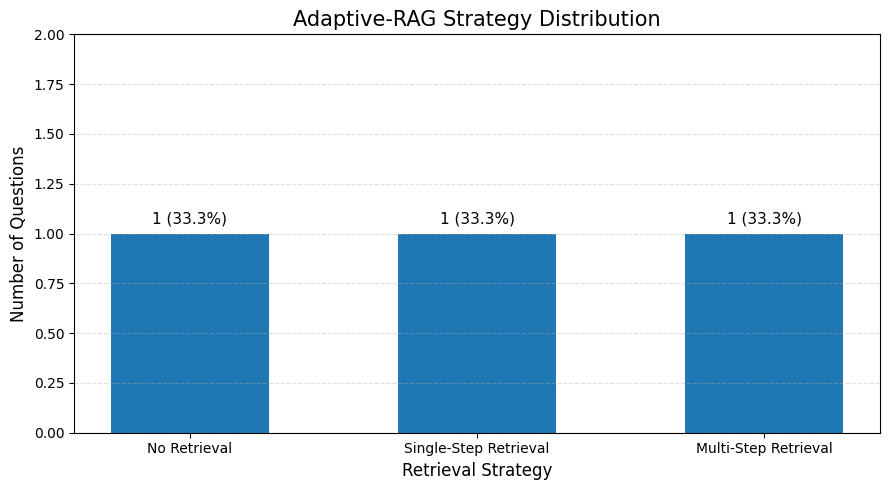

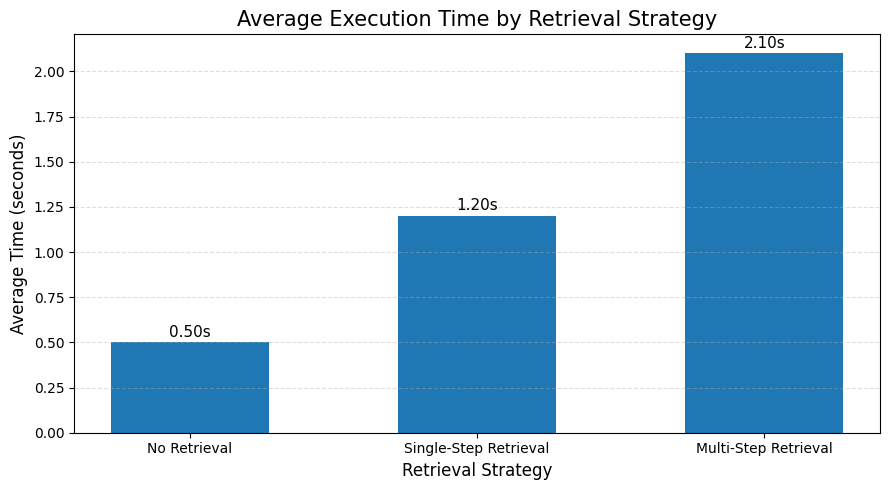

ADAPTIVE-RAG RESULT SUMMARY
--------------------------------

Strategy Distribution:
Selected Strategy
No Retrieval             1
Single-Step Retrieval    1
Multi-Step Retrieval     1
Name: count, dtype: int64

Average Execution Time:
Selected Strategy
No Retrieval             0.5
Single-Step Retrieval    1.2
Multi-Step Retrieval     2.1
Name: Execution Time (sec), dtype: float64

Total Questions: 3
Overall Average Execution Time: 1.267 seconds


In [9]:
# ==========================================
# ADAPTIVE-RAG: RESULT VISUALIZATION
# ==========================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Count questions for each strategy
strategy_order = [
    "No Retrieval",
    "Single-Step Retrieval",
    "Multi-Step Retrieval"
]

strategy_counts = (
    results["Selected Strategy"]
    .value_counts()
    .reindex(strategy_order, fill_value=0)
)

# Calculate average execution time
strategy_time = (
    results.groupby("Selected Strategy")["Execution Time (sec)"]
    .mean()
    .reindex(strategy_order, fill_value=0)
)

# ------------------------------------------
# GRAPH 1: STRATEGY DISTRIBUTION
# ------------------------------------------

plt.figure(figsize=(9, 5))

bars = plt.bar(
    strategy_counts.index,
    strategy_counts.values,
    width=0.55
)

plt.title("Adaptive-RAG Strategy Distribution", fontsize=15)
plt.xlabel("Retrieval Strategy", fontsize=12)
plt.ylabel("Number of Questions", fontsize=12)

plt.ylim(0, max(strategy_counts.max() + 1, 2))
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar, value in zip(bars, strategy_counts.values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.05,
        f"{value} ({value/len(results)*100:.1f}%)",
        ha="center",
        fontsize=11
    )

plt.tight_layout()
plt.show()


# ------------------------------------------
# GRAPH 2: EXECUTION TIME COMPARISON
# ------------------------------------------

plt.figure(figsize=(9, 5))

bars = plt.bar(
    strategy_time.index,
    strategy_time.values,
    width=0.55
)

plt.title("Average Execution Time by Retrieval Strategy", fontsize=15)
plt.xlabel("Retrieval Strategy", fontsize=12)
plt.ylabel("Average Time (seconds)", fontsize=12)

plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar, value in zip(bars, strategy_time.values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.03,
        f"{value:.2f}s",
        ha="center",
        fontsize=11
    )

plt.tight_layout()
plt.show()


# ------------------------------------------
# RESULT SUMMARY
# ------------------------------------------

print("ADAPTIVE-RAG RESULT SUMMARY")
print("--------------------------------")

print("\nStrategy Distribution:")
print(strategy_counts)

print("\nAverage Execution Time:")
print(strategy_time)

print("\nTotal Questions:", len(results))
print("Overall Average Execution Time:",
      round(results["Execution Time (sec)"].mean(), 3), "seconds")

Result Analysis

The implementation demonstrates the core concept of the proposed Adaptive-RAG framework. It dynamically selects a retrieval strategy based on the complexity of the input question.

The first graph represents the distribution of questions across three retrieval strategies: No Retrieval, Single-Step Retrieval, and Multi-Step Retrieval. Simple questions are handled directly by the language model, moderate questions use a single retrieval step, and complex questions use multiple retrieval steps.

The second graph compares the average execution time of each retrieval strategy. It helps illustrate the computational cost associated with different retrieval approaches. Generally, multi-step retrieval requires more processing because it involves repeated retrieval and generation.

Observations
1. No Retrieval: Suitable for simple questions that can be answered using the language model's existing knowledge.
2. Single-Step Retrieval: Retrieves relevant information once before generating an answer.
3. Multi-Step Retrieval: Performs multiple retrieval operations to handle complex questions requiring information from different sources.
4. Adaptive Selection: The framework aims to balance answer quality and computational efficiency by selecting an appropriate retrieval strategy.

## Result analysis and limitations

- The implementation demonstrates the paper's central adaptive decision: route each query to no retrieval, one retrieval step, or iterative multi-step retrieval.
- BM25 is used for document retrieval, consistent with the paper's sparse-retrieval setup.
- The routing accuracy and retrieval-step/time summary above are **only for this tiny demonstration set**. They are not comparable to the paper's benchmark results.
- Differences from the paper: TF-IDF + Logistic Regression replaces T5-Large; the corpus is a small local example rather than the paper's Wikipedia/open-domain QA corpora; extractive sentence selection replaces FLAN-T5/GPT answer generation; and the multi-step follow-up query is a lightweight approximation of iterative reasoning.
- Main limitation: the small classifier and corpus cannot generalize reliably. A full reproduction would use the paper's automatically constructed complexity labels, T5-Large classifier, benchmark datasets, BM25 corpora, and LLM generators.

**Paper:** Jeong et al., “Adaptive-RAG: Learning to Adapt Retrieval-Augmented Large Language Models through Question Complexity,” NAACL 2024.

Possible Improvements

1. Larger Dataset: Use a larger and more diverse question-answering dataset to evaluate the Adaptive-RAG framework under different levels of question complexity.

2. Improved Complexity Classifier: Train the classifier using more high-quality labelled questions to improve the accuracy of selecting retrieval strategies.

3. Better Retrieval Techniques: Replace basic retrieval methods with advanced techniques such as dense retrieval and hybrid search to improve the relevance of retrieved documents.

4. Advanced Language Models: Experiment with more powerful language models to generate accurate, relevant, and context-aware answers.